In [4]:
# 14. Develop an FNN model to classify images into ten different object 
# categories. Perform preprocessing, model training and testing, and 
# display predicted class labels. Use – Dataset - CIFAR-10

In [9]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

In [10]:
df = pd.read_csv('cifar-10.csv')

print(df.head())
print("Dataset shape:", df.shape)

   pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0       59       43       50       68       98      119      139      145   
1      154      126      105      102      125      155      172      180   
2      255      253      253      253      253      253      253      253   
3       28       37       38       42       44       40       40       24   
4      170      168      177      183      181      177      181      184   

   pixel_8  pixel_9  ...  pixel_3063  pixel_3064  pixel_3065  pixel_3066  \
0      149      149  ...          58          65          59          46   
1      142      111  ...          42          67         101         122   
2      253      253  ...          83          80          69          66   
3       32       43  ...          39          59          42          44   
4      189      189  ...          88          85          82          83   

   pixel_3067  pixel_3068  pixel_3069  pixel_3070  pixel_3071  label  
0        

In [11]:
X = df.drop('label', axis=1).values
y = df['label'].values

print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (50000, 3072)
Labels shape: (50000,)


In [12]:
# Normalize pixel values
X = X.astype('float32') / 255.0

# Reshape images
X = X.reshape(-1, 3, 32, 32)
X = X.transpose(0, 2, 3, 1)

# Keep image format for displaying predictions
X_images = X.copy()

# Flatten images for FNN
X = X.reshape(X.shape[0], 3072)

print("Image shape:", X_images.shape)
print("Flattened data shape:", X.shape)

Image shape: (50000, 32, 32, 3)
Flattened data shape: (50000, 3072)


In [13]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (40000, 3072)
Testing data: (10000, 3072)


In [14]:
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

print("Number of classes:", len(class_names))

Number of classes: 10


In [15]:
model = Sequential([
    Input(shape=(3072,)),

    Dense(512, activation='relu'),

    Dropout(0.3),

    Dense(256, activation='relu'),

    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 512)                 │       1,573,376 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [17]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.2538 - loss: 2.0356 - val_accuracy: 0.3135 - val_loss: 1.8740
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.2967 - loss: 1.9057 - val_accuracy: 0.3532 - val_loss: 1.8043
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.3236 - loss: 1.8506 - val_accuracy: 0.3619 - val_loss: 1.7715
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.3338 - loss: 1.8252 - val_accuracy: 0.3647 - val_loss: 1.7749
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.3392 - loss: 1.7975 - val_accuracy: 0.3770 - val_loss: 1.7406
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.3516 - loss: 1.7736 - val_accuracy: 0.3846 - val_loss: 1.7197
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.3536 - loss: 1.7670 - val_accuracy: 0.3800 - val_loss: 1.7264
Epoch 8/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.3607 - loss: 1.7474 - val_accu

In [18]:
test_loss, test_accuracy = model.evaluate(
    x_test, y_test
)

print("Test Loss:", test_loss)

print("Classification Accuracy:",
      test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4001 - loss: 1.6981
Test Loss: 1.6980857849121094
Classification Accuracy: 40.00999927520752 %


In [19]:
predictions = model.predict(x_test[:5])

predicted_labels = np.argmax(predictions, axis=1)

for i in range(5):
    print(
        "Predicted:", class_names[predicted_labels[i]],
        "| Actual:", class_names[y_test[i]]
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
Predicted: Bird | Actual: Bird
Predicted: Deer | Actual: Horse
Predicted: Ship | Actual: Automobile
Predicted: Automobile | Actual: Truck
Predicted: Frog | Actual: Frog


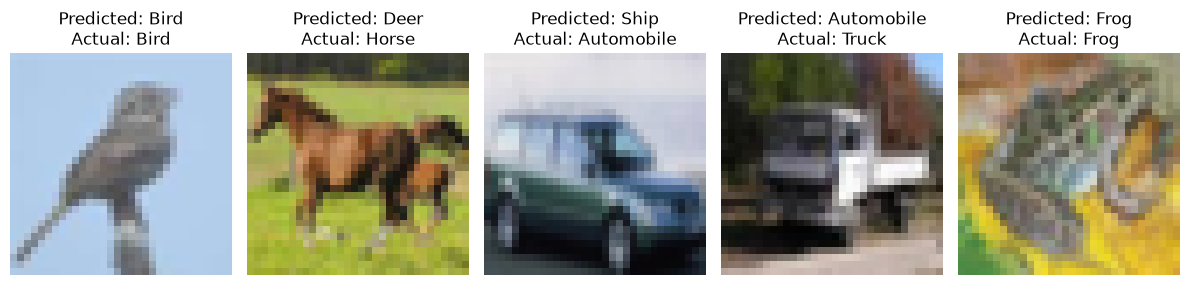

In [20]:
plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(1, 5, i + 1)

    # Convert flattened image back to original shape
    image = x_test[i].reshape(32, 32, 3)

    plt.imshow(image)

    plt.title(
        "Predicted: " + class_names[predicted_labels[i]] +
        "\nActual: " + class_names[y_test[i]]
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

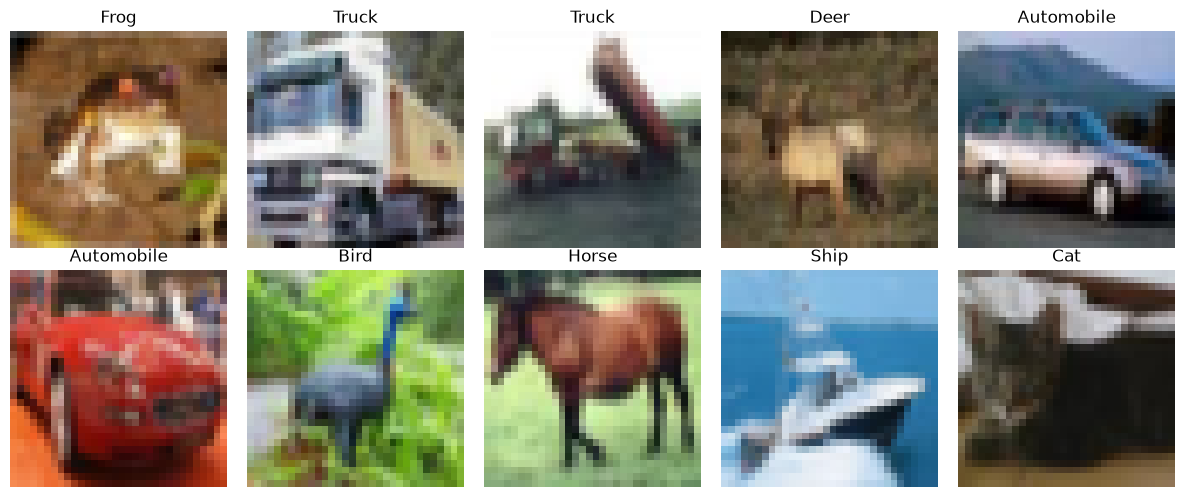

In [21]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_images[i])

    plt.title(class_names[y[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()